<a href="https://colab.research.google.com/github/davidcechak/DL-for-bio-course/blob/master/01_Linear_regression_ADVANCED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pytorch basics

## Model

In [ ]:
# INTRO TO COLAB
# - What is a notebook?
# - Where to Change runtime type: GPU
# - Run all / Restart session and rull all

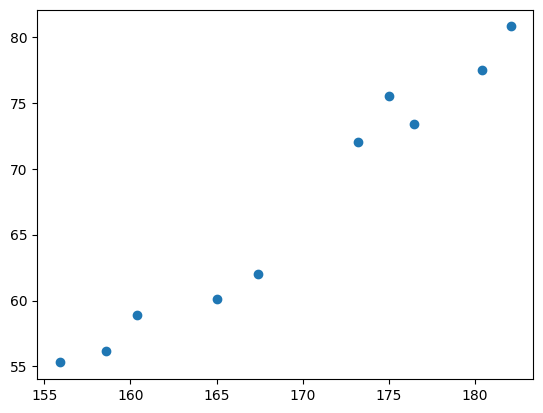

In [ ]:
from matplotlib import pyplot as plt

height = [167.4, 182.1, 175.0, 155.9, 160.4, 180.4, 173.2, 165.0, 158.6, 176.5]
bodyweight = [62.0, 80.8, 75.5, 55.3, 58.9, 77.5, 72.0, 60.1, 56.2, 73.4]
plt.scatter(height,bodyweight)

In [ ]:
import torch.nn as nn
import torch

model = nn.Linear(in_features=1, out_features=1, bias=True)

print(model.weight)
print(model.bias)

Parameter containing:
tensor([[0.0167]], requires_grad=True)
Parameter containing:
tensor([-0.1153], requires_grad=True)


In [ ]:
# Make height a tensor - keeps track of gradients, Turne Shape 10 into Shape 10x1
height_tensor = torch.tensor(height).reshape(-1,1)

# Running through the layer, broadcasting
preds = model.forward(height_tensor)
print(preds)

tensor([[2.6770],
        [2.9222],
        [2.8038],
        [2.4852],
        [2.5602],
        [2.8938],
        [2.7737],
        [2.6370],
        [2.5302],
        [2.8288]], grad_fn=<AddmmBackward0>)


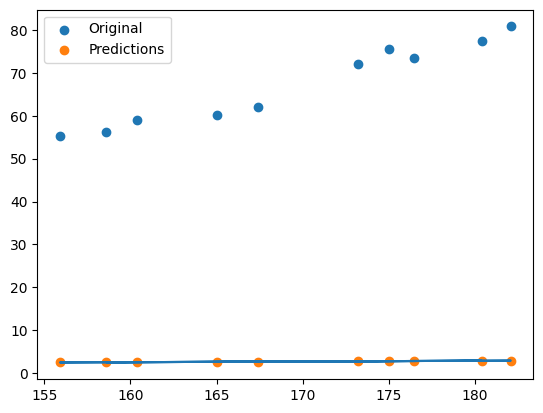

In [ ]:
plt.scatter(height, bodyweight, label='Original')
plt.scatter(height, preds.tolist(), label='Predictions')
plt.plot(height, preds.tolist())
plt.legend()

In [ ]:
x = torch.tensor(height).reshape(-1,1) #Shape 10x1
y = torch.tensor(bodyweight).reshape(-1,1) #Shape 10x1

## Learning

In [ ]:
loss_fn = nn.MSELoss()

print(loss_fn(preds, y)) #takes model output and target
print(loss_fn(y,y))

tensor(4235.3604, grad_fn=<MseLossBackward0>)
tensor(0.)


In [ ]:
loss = loss_fn(preds,y)
loss.backward() # Computing gradients and storing it next to parameters

print(model.weight)
print(model.weight.grad)

Parameter containing:
tensor([[0.0167]], requires_grad=True)
tensor([[-22000.5996]])


In [ ]:
opt = torch.optim.SGD(model.parameters(), lr=1e-5) # lr is Learning rate

opt.step() # Using the gradient of parameters to change them
opt.zero_grad()

print(model.weight)
print(model.weight.grad)

Parameter containing:
tensor([[0.2367]], requires_grad=True)
None


In [ ]:
preds = model.forward(x) # Using the model after updating parameters
loss = loss_fn(preds, y)

print(loss)

tensor(788.6097, grad_fn=<MseLossBackward0>)


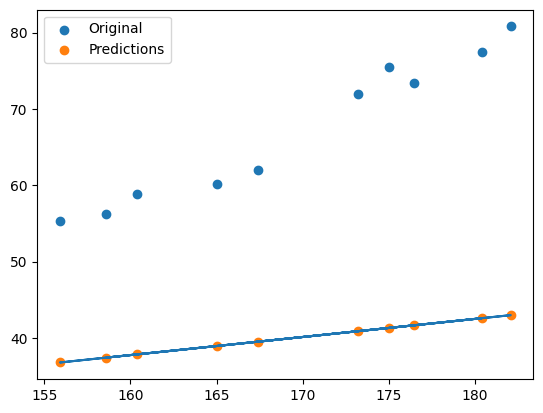

In [ ]:
plt.scatter(x.tolist(), y.tolist(), label='Original')
plt.scatter(x.tolist(), preds.tolist(), label='Predictions')
plt.plot(x.tolist(), preds.tolist())
plt.legend()

# Full solution

In [ ]:
import torch.nn as nn
import torch

model = nn.Linear(in_features=1, out_features=1, bias=True) # Model
opt = torch.optim.SGD(model.parameters(), lr=1e-4) # Optimizer
loss_fn = nn.MSELoss() # Loss function

# Raw Data
x = torch.tensor([167.4, 182.1, 175.0, 155.9, 160.4, 180.4, 173.2, 165.0, 158.6, 176.5]).reshape(-1,1) #Shape 10x1
y = torch.tensor([62.0, 80.8, 75.5, 55.3, 58.9, 77.5, 72.0, 60.1, 56.2, 73.4]).reshape(-1,1) #Shape 10x1

# Normalizing data
x = (x - torch.mean(x))/torch.std(x)
y = (y - torch.mean(y))/torch.std(y)

# Training
num_epochs = 10
# Repeat for given number of epochs
for epoch in range(num_epochs):

    # 1. Generate predictions
    pred = model(x)

    # 2. Calculate loss
    loss = loss_fn(pred, y)

    # 3. Compute gradients
    loss.backward()

    # 4. Update parameters using gradients
    opt.step()

    # 5. Reset the gradients to zero
    opt.zero_grad()

    # Optional: Uncomment to log loss during training
    log_interval = num_epochs//10
    if(epoch%log_interval == 0):
      print(f'Epoch {epoch} loss:',loss.item())

print('Training done')

Epoch 0 loss: 1.2126984596252441
Epoch 1 loss: 1.2122528553009033
Epoch 2 loss: 1.2118070125579834
Epoch 3 loss: 1.2113616466522217
Epoch 4 loss: 1.21091628074646
Epoch 5 loss: 1.2104711532592773
Epoch 6 loss: 1.210026502609253
Epoch 7 loss: 1.2095816135406494
Epoch 8 loss: 1.209136962890625
Epoch 9 loss: 1.2086924314498901
Training done


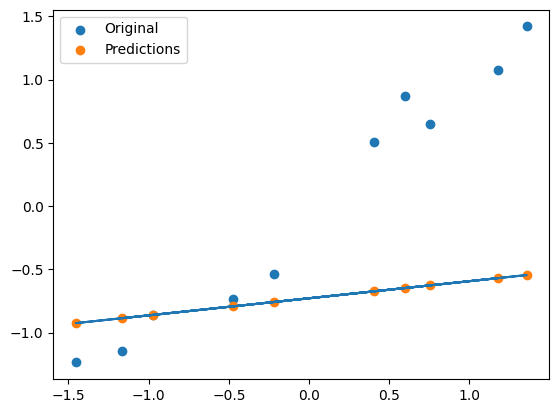

Weight 0.1351078748703003
Bias -0.728321373462677
Loss 1.2082481384277344


In [ ]:
from matplotlib import pyplot as plt
import numpy as np

preds = model(x)
plt.scatter(x.tolist(),y.tolist(), label='Original')
plt.scatter(x.tolist(),preds.tolist() , label='Predictions')
plt.plot(x.tolist(),preds.tolist())
plt.legend()
plt.show()

print('Weight', model.weight.item())
print('Bias', model.bias.item())
print('Loss', loss_fn(model(x), y).item())

In [ ]:
# Exercise
# - Explore which hyperparameters work the best (Number of epochs, Learning rate)
# - Could we change something else than the model to improve?

In [ ]:
new_X = torch.tensor([130.5]) # Predicting a new data point
model(new_X)

tensor([16.9033], grad_fn=<ViewBackward0>)